In [1]:
import orjson as json
import pandas as pd
import random
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
from tqdm.cli import tqdm

In [2]:
from sys import path as sys_path
project_root = Path.cwd().parent.parent
if str(project_root) not in sys_path:
    sys_path.append(str(project_root))
data_dir = project_root/"data/"
outputs_dir = project_root/"outputs/"

In [3]:
from src.year_predictions import pick_year, fill_years

In [4]:
zero_year_page_n_counter = Counter()
zero_year_book_part_counter = Counter()

 ## Process JSONL files

In [5]:
migration_data_directory = Path(outputs_dir / "json/migration_jsonls/2-final")
files = list(migration_data_directory.glob("*_migration_events.jsonl"))

for file in tqdm(files):
    with open(file, "rb") as f:
        for line in f:
            record = json.loads(line)
            year = record["year_prediction"]
            page_n = record["page_n"]

            if year == 0:
                zero_year_page_n_counter[page_n] += 1

                zero_year_book_part_counter[
                    # roughly book progress as percent
                    int(100 * (page_n / record["image_range_end"]))
                ] += 1

100%|██████████| 468/468 [00:19<00:00, 23.79it/s]


In [6]:
zero_year_page_n_counter_as_list = []
for page, count in zero_year_page_n_counter.items():
    zero_year_page_n_counter_as_list.extend([page] * count)

zero_year_book_part_counter_as_list = []
for part, count in zero_year_book_part_counter.items():
    zero_year_book_part_counter_as_list.extend([part] * count)

Text(0.5, 0, 'Progress (%)')

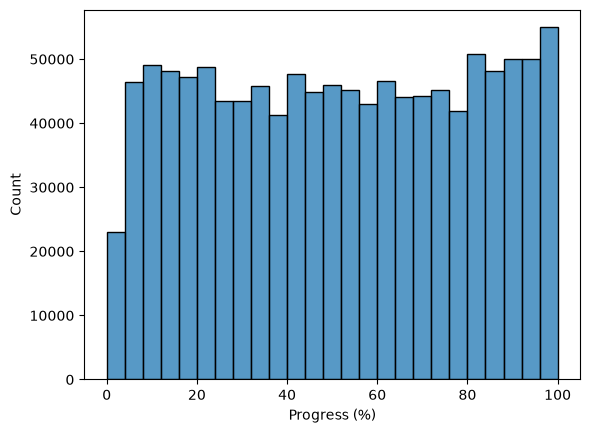

In [7]:
sns.histplot(
    zero_year_book_part_counter_as_list, bins=25
).set_xlabel("Progress (%)")

## Inspecting random books with zero years

In [8]:
year_prediction_dir = data_dir/"year-predictions"

In [9]:
year_predictions_files = year_prediction_dir.glob("*.jsonl")
all_year_objects = []
for file in year_predictions_files:
    with open(file, "rb") as fp:
        all_year_objects.extend(json.loads(line) for line in fp)

In [10]:
all_year_data = pd.DataFrame.from_dict(
    all_year_objects
)

In [11]:
all_year_data["page"] = all_year_data["page"].astype(int)

In [12]:
all_year_data["year_prediction"] = pick_year(all_year_data)

In [13]:
book_groups = all_year_data.groupby("book")

LOW, HIGH = 1/5, 4/5

zero_fraction = book_groups["year_prediction"].agg(lambda s: (s == 0).mean())

low_books = list(zero_fraction[(zero_fraction <= LOW) & (zero_fraction > 0)].index)
mid_books = list(zero_fraction[(zero_fraction > LOW) & (zero_fraction < HIGH)].index)
high_books = list(zero_fraction[zero_fraction >= HIGH].index)

In [19]:
random.seed(42)
book = random.choice(high_books)

Text(0.5, 0.98, 'sysma_muuttaneet_1883-1904_ap_ulos')

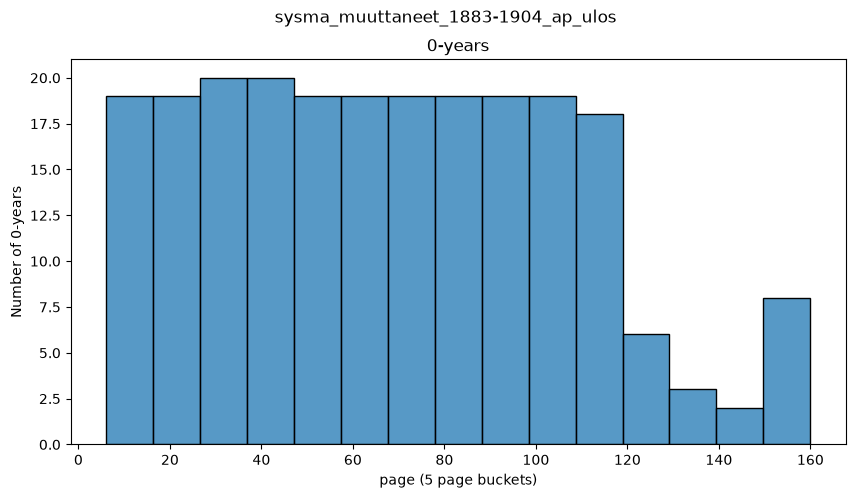

In [20]:
book_df = book_groups.get_group(book)

plot_df = book_df[["page", "year_prediction"]]

n_pages = len(plot_df["page"].unique())
if n_pages <= 5:
    binwidth = 1
elif n_pages < 100:
    binwidth = 5
elif n_pages >= 100:
    binwidth = 10

if binwidth <= 1:
    display(book_df)
    assert(binwidth > 1), "Not enough 0-year pages for histogram"

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
sns.histplot(
    plot_df[plot_df["year_prediction"] == 0]["page"], binwidth=binwidth,
    ax=ax
)

ax.set_xlabel("page (5 page buckets)")
ax.set_ylabel("Number of 0-years")
ax.set_title("0-years")

fig.suptitle(book)

Seems like filling some years in between here would be possible and useful.

## Filling years

In [21]:
all_year_data = fill_years(all_year_data)

## Comparing impact of filling more years:

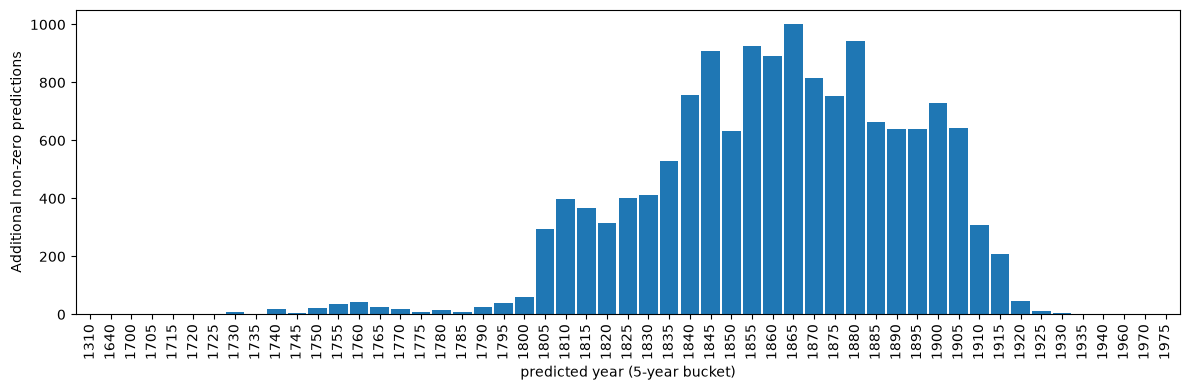

In total, 14583 more non 0-year pages


In [22]:
filled = all_year_data["year_prediction_filled"]
original = all_year_data["year_prediction"]

filled_counts = (filled[filled != 0] // 5 * 5).value_counts().sort_index()
original_counts = (
    (original[original != 0] // 5 * 5).value_counts().sort_index()
)
gain = filled_counts.sub(original_counts, fill_value=0)

ax = gain.plot.bar(figsize=(12, 4), width=0.9)
ax.set_xlabel("predicted year (5-year bucket)")
ax.set_ylabel("Additional non-zero predictions")
plt.tight_layout()
plt.show()

print(
    f"In total, {filled_counts.sum() - original_counts.sum()} more non 0-year pages"
)

### Single-book example

Let's check out the same book as before

Text(0.5, 0.98, 'sysma_muuttaneet_1883-1904_ap_ulos')

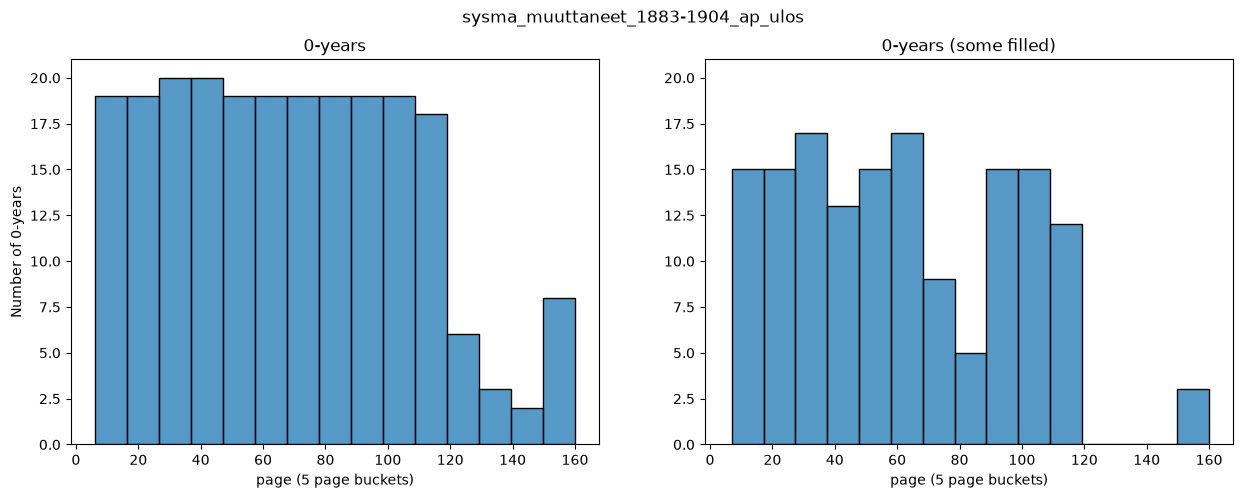

In [23]:
book_df = book_groups.get_group(book)

plot_df = book_df[["page", "year_prediction", "year_prediction_filled"]]

n_pages = len(plot_df["page"].unique())
if n_pages <= 5:
    binwidth = 1
elif n_pages < 100:
    binwidth = 5
elif n_pages >= 100:
    binwidth = 10

if binwidth <= 1:
    display(book_df)
    assert(binwidth > 1), "Not enough 0-year pages for histogram"

fig, axs = plt.subplots(1, 2, figsize=(15, 5), sharex=True, sharey=True)
sns.histplot(
    plot_df[plot_df["year_prediction"] == 0]["page"], binwidth=binwidth,
    ax=axs[0]
)
sns.histplot(
    plot_df[plot_df["year_prediction_filled"] == 0]["page"], binwidth=binwidth,
    ax=axs[1]
)
axs[0].set_xlabel("page (5 page buckets)")
axs[0].set_ylabel("Number of 0-years")
axs[1].set_xlabel("page (5 page buckets)")
axs[1].set_ylabel("Number of 0-years")
axs[0].set_title("0-years")
axs[1].set_title("0-years (some filled)")

axs[1].yaxis.set_tick_params(labelleft=True)

fig.suptitle(book)

Less 0-years this time